# 04 · Model experiments (Module 6)

**Selection protocol (doc §10).** This is identical for every run in this notebook.

1. **Tune** each model on **train** and score it on **validation**.
   - Candidates: Linear Regression (ridge with region × forecast interactions), Random Forest and XGBoost.
   - Each is tried with two targets: predicting NASA radiation *directly*, or the *residual* correction (NASA − raw forecast).
2. **Run the regional ablation (§10.4)** with each model's best settings: location-blind vs region-aware vs per-region.
3. **Select** the configuration with the lowest validation MAE. It must beat the raw forecast on validation.
4. **Refit** it on **train + validation**, because the most recent data matters given the drift seen in the EDA. Then score it on **test** against the baselines.

**How this notebook unfolded.**

- The first run (**v1**, all features) is shown as it was run.
- Its test result revealed that ECMWF's archived **cloud-cover** forecasts changed behaviour from late 2025 (§4).
- That was diagnosed from forecast *inputs only*, without labels, which is a check a live system can also run.
- The protocol was then re-run without that feature (**v2**), and v2 is the model saved for deployment.
- Both test results are reported.

All errors are in kWh/m²/day.

In [1]:
import sys, json, time, itertools
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", "{:.3f}".format)

from src.viz import set_style, REGION_ORDER, REGION_LABEL, INK_2
from src.models.train import build_estimator, FEATURE_SETS
from src.models.evaluate import regression_metrics, grouped_metrics, evaluation_table
from src.preprocessing.build_training_data import load_config, FEATURES, TARGET

set_style()
cfg = load_config()
data = pd.read_csv(ROOT / "data" / "processed" / "solar_model_training.csv", parse_dates=["target_date"])
train, val, test = (data[data["split"] == s].copy() for s in ("train", "validation", "test"))
trval = pd.concat([train, val])
RES = ROOT / "results" / "models"; RES.mkdir(parents=True, exist_ok=True)
MODELS = ROOT / "models"; MODELS.mkdir(exist_ok=True)
C_MODEL, C_RAW = "#2a78d6", "#eb6834"   # categorical slots 1-2 (validated palette)
print({s: len(d) for s, d in [("train", train), ("validation", val), ("test", test)]})

{'train': 5060, 'validation': 2208, 'test': 4296}


## 1. Reference scores on validation

- **`raw_forecast`** and **`climatology`** are the two baselines required by the doc (§10.3).
- **`bias_corrected_forecast`** is an extra reference: the raw forecast minus its mean error for each region and lead, taken from the fitting data. If an ML model cannot beat this one-line correction, it is not adding much.

In [2]:
def bias_table(df):
    return (df["forecast_shortwave_radiation"] - df[TARGET]).groupby([df["region_id"], df["lead_days"]]).mean().rename("b")

def bias_corrected(df, table):
    return df["forecast_shortwave_radiation"] - df.join(table, on=["region_id", "lead_days"])["b"]

ref_val = {
    "raw_forecast": regression_metrics(val[TARGET], val["forecast_shortwave_radiation"]),
    "climatology": regression_metrics(val[TARGET], val["climatology_solar_radiation"]),
    "bias_corrected_forecast": regression_metrics(val[TARGET], bias_corrected(val, bias_table(train))),
}
pd.DataFrame(ref_val).T[["mae", "rmse", "r2", "bias"]]

,mae,rmse,r2,bias
raw_forecast,0.785,1.061,0.450,0.324
climatology,1.038,1.336,0.127,0.290
bias_corrected_forecast,0.762,1.013,0.498,0.060


## 2. The protocol as a function

The tuning grids are deliberately small. With about 420 training days, which cover each season only once, heavily tuned trees overfit.

In [3]:
GRIDS = {
    "linear": {"alpha": [0.1, 1.0, 10.0, 100.0]},
    "random_forest": {"max_depth": [6, 10, None], "min_samples_leaf": [5, 20, 50], "max_features": [0.33, 0.6]},
    "xgboost": {"max_depth": [2, 3, 4], "learning_rate": [0.02, 0.05], "n_estimators": [200, 500],
                "min_child_weight": [5, 20]},
}
PRED_COLS = {"ml_model": "ml_prediction", "raw_forecast": "forecast_shortwave_radiation",
             "bias_corrected_forecast": "bias_corrected_forecast", "climatology": "climatology_solar_radiation"}

def grid(space):
    for values in itertools.product(*space.values()):
        yield dict(zip(space, values))

def run_protocol(exclude=(), tag="v"):
    t0 = time.time()
    # 1. tuning (region-aware features), train -> validation
    rows = []
    for kind, space in GRIDS.items():
        for target in ("direct", "residual"):
            for p in grid(space):
                m = build_estimator(kind, "region_aware", target, exclude=exclude, **p).fit(train, train[TARGET])
                rows.append({"model": kind, "target": target, "params": json.dumps(p),
                             **regression_metrics(val[TARGET], m.predict(val))})
    tuning = pd.DataFrame(rows)
    best = tuning.loc[tuning.groupby(["model", "target"])["mae"].idxmin()].sort_values("mae")
    # 2. regional ablation with best params
    abl = []
    for _, b in best.iterrows():
        p = json.loads(b["params"])
        for variant in ("location_blind", "region_aware", "per_region"):
            m = build_estimator(b["model"], variant, b["target"], exclude=exclude, **p).fit(train, train[TARGET])
            pred = m.predict(val)
            reg = grouped_metrics(val.assign(pred=pred), TARGET, "pred", ["region_id"]).set_index("region_id")["mae"]
            abl.append({"model": b["model"], "target": b["target"], "variant": variant, "params": b["params"],
                        **regression_metrics(val[TARGET], pred), **{f"mae_{r}": reg[r] for r in REGION_ORDER}})
    ablation = pd.DataFrame(abl).sort_values("mae").reset_index(drop=True)
    ablation["label"] = ablation["model"] + " · " + ablation["variant"] + " · " + ablation["target"]
    # 3. selection
    selected = ablation.iloc[0]
    assert selected["mae"] < ref_val["raw_forecast"]["mae"], "no model beats the raw forecast on validation"
    # 4. refit on train+validation, score on test
    params = json.loads(selected["params"])
    final = build_estimator(selected["model"], selected["variant"], selected["target"], exclude=exclude, **params)
    final.fit(trval, trval[TARGET])
    te = test.assign(ml_prediction=final.predict(test), bias_corrected_forecast=bias_corrected(test, bias_table(trval)))
    test_eval = evaluation_table(te, TARGET, PRED_COLS)
    tuning.to_csv(RES / f"tuning_{tag}.csv", index=False)
    ablation.to_csv(RES / f"ablation_validation_{tag}.csv", index=False)
    test_eval.to_csv(RES / f"test_metrics_{tag}.csv", index=False)
    print(f"[{tag}] {len(tuning) + len(ablation) + 1} fits in {time.time() - t0:.0f}s | selected: {selected['label']} {params} | val MAE {selected['mae']:.3f}")
    return {"tag": tag, "exclude": list(exclude), "best": best, "ablation": ablation, "selected": selected,
            "params": params, "final": final, "test_pred": te, "test_eval": test_eval}

def show_ablation(r):
    piv = r["ablation"].pivot_table(index=["model", "target"], columns="variant", values="mae")[["location_blind", "region_aware", "per_region"]]
    piv["region_aware − blind"] = piv["region_aware"] - piv["location_blind"]
    return piv

def show_test(r, scope="overall"):
    t = r["test_eval"][r["test_eval"]["scope"] == scope]
    if scope == "overall":
        return t.set_index("model")[["mae", "rmse", "r2", "bias"]]
    t = t.pivot(index="group", columns="model", values="mae")[list(PRED_COLS)]
    t["ml vs raw (%)"] = 100 * (t["ml_model"] / t["raw_forecast"] - 1)
    return t.rename(index=REGION_LABEL)

## 3. Run v1: all features

In [4]:
v1 = run_protocol(exclude=(), tag="v1_all_features")
v1["best"][["model", "target", "params", "mae", "rmse", "r2", "bias"]]

[v1_all_features] 111 fits in 124s | selected: linear · region_aware · direct {'alpha': 100.0} | val MAE 0.727


,model,target,params,mae,rmse,r2,bias
3,linear,direct,"{""alpha"": 100.0}",0.727,0.926,0.581,-0.003
7,linear,residual,"{""alpha"": 100.0}",0.727,0.930,0.577,0.005
76,xgboost,residual,"{""max_depth"": 3, ""learning_rate"": 0.02, ""n_est...",0.730,0.940,0.568,0.033
27,random_forest,residual,"{""max_depth"": 6, ""min_samples_leaf"": 5, ""max_f...",0.732,0.943,0.565,0.032
8,random_forest,direct,"{""max_depth"": 6, ""min_samples_leaf"": 5, ""max_f...",0.735,0.927,0.580,-0.035
60,xgboost,direct,"{""max_depth"": 4, ""learning_rate"": 0.02, ""n_est...",0.736,0.935,0.573,-0.005


In [5]:
show_ablation(v1)

variant                 location_blind  region_aware  per_region  region_aware − blind
model         target                                                                  
linear        direct             0.735         0.727       0.734                -0.008
              residual           0.738         0.727       0.743                -0.011
random_forest direct             0.731         0.735       0.753                 0.004
              residual           0.734         0.732       0.773                -0.001
xgboost       direct             0.729         0.736       0.760                 0.007
              residual           0.736         0.730       0.764                -0.006

In [6]:
display(show_test(v1)); display(show_test(v1, "lead")); display(show_test(v1, "region"))

,mae,rmse,r2,bias
model,,,,
ml_model,0.654,0.854,0.585,-0.190
raw_forecast,0.711,0.990,0.442,0.451
bias_corrected_forecast,0.624,0.888,0.552,0.169
climatology,0.773,1.064,0.356,0.082


model,ml_model,raw_forecast,bias_corrected_forecast,climatology,ml vs raw (%)
group,,,,,
1,0.634,0.651,0.565,0.773,-2.555
2,0.655,0.729,0.637,0.773,-10.162
3,0.673,0.754,0.671,0.773,-10.733


model,ml_model,raw_forecast,bias_corrected_forecast,climatology,ml vs raw (%)
group,,,,,
Karaikal,0.673,0.684,0.601,0.815,-1.682
Mahe,0.575,0.646,0.627,0.690,-11.017
Puducherry,0.639,0.680,0.588,0.753,-6.011
Yanam,0.729,0.835,0.681,0.835,-12.614


**v1 observations**

- **Selected:** region-aware ridge regression (direct target), with validation MAE **0.727**. That beats the raw forecast (0.785) and the bias-corrected forecast (0.762).
- **The regional ablation was inconclusive.** Region-aware vs location-blind differs by at most ±0.01 kWh/m²/day, which is within noise. Per-region models were consistently worst, as expected with about 420 training days split four ways.
- **Test:** MAE 0.654, which is 8 % better than the raw forecast. **But the bias flips sign to −0.19**, and the trivial bias-corrected forecast has a lower test MAE (0.624). Something changed between training and test, and §4 diagnoses it.

## 4. Diagnosis: archived forecast inputs drifted

In v1 the ML model **under**-predicts on test (bias −0.19), even though the raw forecast **over**-predicts (+0.45).

To find out why, each forecast input is compared with the same calendar months a year earlier. This uses **forecast inputs only, not NASA labels**, so a deployed system can run the same check.

In [7]:
fc = data[data["lead_days"] == 1]
cloud = fc.groupby([fc["target_date"].dt.year.rename("year"), fc["target_date"].dt.month.rename("month")])["forecast_cloud_cover_mean"].mean().unstack()
print("Mean ECMWF forecast cloud cover (%), lead 1, all regions")
cloud.round(0)

Mean ECMWF forecast cloud cover (%), lead 1, all regions


month,1,2,3,4,5,6,7,8,9,10,11,12
year,,,,,,,,,,,,
2024,NaN,NaN,6.000,10.000,37.000,61.000,69.000,64.000,49.000,50.000,43.000,43.000
2025,22.000,6.000,13.000,16.000,41.000,56.000,62.000,62.000,55.000,57.000,54.000,49.000
2026,37.000,36.000,22.000,38.000,60.000,75.000,90.000,86.000,68.000,66.000,83.000,NaN


In [8]:
# year-over-year shift of each input, Apr-Oct (present in all three years), in units of the feature's std
cols = ["forecast_shortwave_radiation", "forecast_cloud_cover_mean", "forecast_humidity_mean", "forecast_precipitation_sum",
        "forecast_temperature_mean", "forecast_temperature_max", "forecast_temperature_min", "forecast_wind_speed_mean"]
m = fc.groupby(["region_id", fc["target_date"].dt.to_period("M").rename("ym")])[cols].mean()
shift = {}
for new, old in [(2025, 2024), (2026, 2025)]:
    d = [(m.xs(pd.Period(f"{new}-{mo:02d}", "M"), level="ym") - m.xs(pd.Period(f"{old}-{mo:02d}", "M"), level="ym")) / fc[cols].std()
         for mo in range(4, 11)]
    shift[f"{new} vs {old}"] = pd.concat(d).mean()
pd.DataFrame(shift)

,2025 vs 2024,2026 vs 2025
forecast_shortwave_radiation,-0.048,0.390
forecast_cloud_cover_mean,0.041,0.590
forecast_humidity_mean,0.097,-0.180
forecast_precipitation_sum,0.072,-0.142
forecast_temperature_mean,-0.276,0.344
forecast_temperature_max,-0.271,0.338
forecast_temperature_min,-0.246,0.265
forecast_wind_speed_mean,-0.034,0.140


**Diagnosis**

- **Forecast cloud cover rose by 15–35 percentage points in every month of 2026** compared with 2025, including dry-season months. That is a shift of about 0.6 standard deviations, against 0.04 between 2024 and 2025. The jump starts around October–November 2025.
- **This is not a real weather change.** Over the same months, *forecast radiation* also went **up** (+0.39 sd), and NASA radiation rose as well. More cloud together with more sunshine is physically inconsistent. The likely cause is a change in how the ECMWF cloud-cover field is produced or delivered: a model-cycle upgrade or a change in Open-Meteo's processing. The exact cause is not confirmed here.
- **The other inputs shifted in ways that fit a warmer, sunnier 2026,** so they are kept.
- **Consequence:** v1 learned "more cloud → less sun" from 2024–25. Fed with the inflated 2026 cloud values, it under-predicts. Live forecasts in November 2026 have the same inflated behaviour, so **v1 would be wrong in deployment whatever its test score.**
- **Decision:** drop `forecast_cloud_cover_mean` and re-run the identical protocol (v2). This is the forecast-model consistency risk the doc anticipated in §16 item 3. Module 7 should monitor input drift.

## 5. Run v2: without forecast cloud cover

In [9]:
DRIFTED = ("forecast_cloud_cover_mean",)
v2 = run_protocol(exclude=DRIFTED, tag="v2_no_cloud_cover")
v2["best"][["model", "target", "params", "mae", "rmse", "r2", "bias"]]

[v2_no_cloud_cover] 111 fits in 120s | selected: random_forest · location_blind · direct {'max_depth': 6, 'min_samples_leaf': 5, 'max_features': 0.6} | val MAE 0.732


,model,target,params,mae,rmse,r2,bias
76,xgboost,residual,"{""max_depth"": 3, ""learning_rate"": 0.02, ""n_est...",0.736,0.946,0.563,0.034
26,random_forest,residual,"{""max_depth"": 6, ""min_samples_leaf"": 5, ""max_f...",0.736,0.952,0.557,0.040
60,xgboost,direct,"{""max_depth"": 4, ""learning_rate"": 0.02, ""n_est...",0.744,0.942,0.566,0.001
7,linear,residual,"{""alpha"": 100.0}",0.745,0.952,0.557,0.013
0,linear,direct,"{""alpha"": 0.1}",0.746,0.952,0.557,0.016
9,random_forest,direct,"{""max_depth"": 6, ""min_samples_leaf"": 5, ""max_f...",0.750,0.944,0.564,-0.019


In [10]:
show_ablation(v2)

variant                 location_blind  region_aware  per_region  region_aware − blind
model         target                                                                  
linear        direct             0.747         0.746       0.763                -0.002
              residual           0.747         0.745       0.751                -0.002
random_forest direct             0.732         0.750       0.776                 0.018
              residual           0.737         0.736       0.770                -0.001
xgboost       direct             0.736         0.744       0.781                 0.008
              residual           0.735         0.736       0.766                 0.001

In [11]:
display(show_test(v2)); display(show_test(v2, "lead")); display(show_test(v2, "region"))

,mae,rmse,r2,bias
model,,,,
ml_model,0.595,0.837,0.602,0.105
raw_forecast,0.711,0.990,0.442,0.451
bias_corrected_forecast,0.624,0.888,0.552,0.169
climatology,0.773,1.064,0.356,0.082


model,ml_model,raw_forecast,bias_corrected_forecast,climatology,ml vs raw (%)
group,,,,,
1,0.542,0.651,0.565,0.773,-16.689
2,0.604,0.729,0.637,0.773,-17.059
3,0.640,0.754,0.671,0.773,-15.146


model,ml_model,raw_forecast,bias_corrected_forecast,climatology,ml vs raw (%)
group,,,,,
Karaikal,0.589,0.684,0.601,0.815,-13.974
Mahe,0.550,0.646,0.627,0.690,-14.881
Puducherry,0.568,0.680,0.588,0.753,-16.428
Yanam,0.675,0.835,0.681,0.835,-19.100


## 6. v1 vs v2

In [12]:
cmp = []
for r in (v1, v2):
    o = r["test_eval"].query("scope == 'overall' and model == 'ml_model'").iloc[0]
    cmp.append({"run": r["tag"], "selected": r["selected"]["label"], "val MAE": r["selected"]["mae"],
                "test MAE": o["mae"], "test RMSE": o["rmse"], "test R²": o["r2"], "test bias": o["bias"]})
raw = v1["test_eval"].query("scope == 'overall' and model == 'raw_forecast'").iloc[0]
bc = v1["test_eval"].query("scope == 'overall' and model == 'bias_corrected_forecast'").iloc[0]
cmp.append({"run": "raw_forecast", "selected": "-", "val MAE": ref_val["raw_forecast"]["mae"], "test MAE": raw["mae"],
            "test RMSE": raw["rmse"], "test R²": raw["r2"], "test bias": raw["bias"]})
cmp.append({"run": "bias_corrected_forecast", "selected": "-", "val MAE": ref_val["bias_corrected_forecast"]["mae"], "test MAE": bc["mae"],
            "test RMSE": bc["rmse"], "test R²": bc["r2"], "test bias": bc["bias"]})
comparison = pd.DataFrame(cmp).set_index("run")
comparison.to_csv(RES / "v1_v2_comparison.csv")
comparison

,selected,val MAE,test MAE,test RMSE,test R²,test bias
run,,,,,,
v1_all_features,linear · region_aware · direct,0.727,0.654,0.854,0.585,-0.190
v2_no_cloud_cover,random_forest · location_blind · direct,0.732,0.595,0.837,0.602,0.105
raw_forecast,-,0.785,0.711,0.990,0.442,0.451
bias_corrected_forecast,-,0.762,0.624,0.888,0.552,0.169


### Validation MAE of every v2 configuration (the selection view)

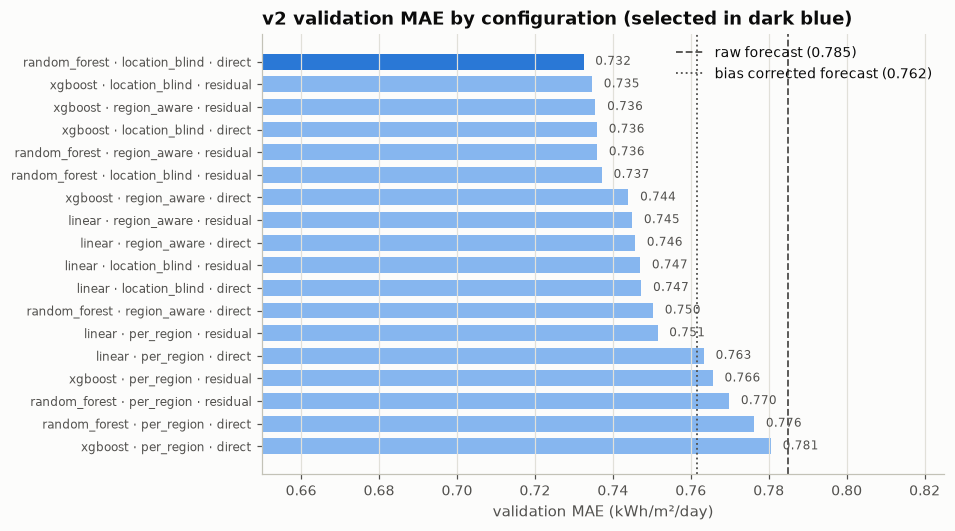

In [13]:
cands = v2["ablation"]
fig, ax = plt.subplots(figsize=(8, 5.2))
y = np.arange(len(cands))
ax.barh(y, cands["mae"], color=[C_MODEL if i == 0 else "#86b6ef" for i in range(len(cands))], height=0.7)
ax.set_yticks(y, cands["label"], fontsize=8); ax.invert_yaxis()
for name, ls in [("raw_forecast", "--"), ("bias_corrected_forecast", ":")]:
    ax.axvline(ref_val[name]["mae"], color=INK_2, ls=ls, lw=1.2,
               label=f"{name.replace('_', ' ')} ({ref_val[name]['mae']:.3f})")
ax.legend(loc="upper right")
for yi, v in zip(y, cands["mae"]):
    ax.text(v + 0.003, yi, f"{v:.3f}", va="center", fontsize=8, color=INK_2)
ax.set_xlim(0.65, max(cands["mae"].max(), ref_val["raw_forecast"]["mae"]) + 0.04)
ax.grid(axis="x"); ax.grid(axis="y", visible=False)
ax.set_xlabel("validation MAE (kWh/m²/day)"); ax.set_title("v2 validation MAE by configuration (selected in dark blue)")
fig.savefig(RES / "validation_comparison.png"); plt.show()

### Test error by month: final model (v2) vs raw forecast

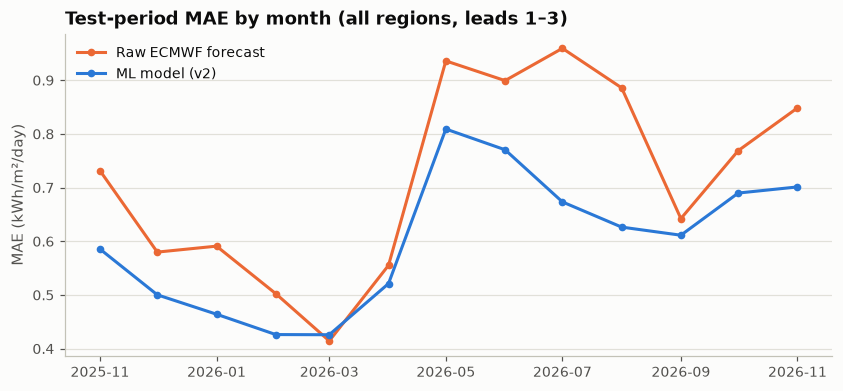

target_date,2025-11,2025-12,2026-01,2026-02,2026-03,2026-04,2026-05,2026-06,2026-07,2026-08,2026-09,2026-10,2026-11
raw_forecast_mae,0.732,0.580,0.591,0.503,0.415,0.555,0.936,0.899,0.960,0.886,0.642,0.769,0.849
ml_v2_mae,0.586,0.500,0.464,0.426,0.426,0.521,0.809,0.771,0.673,0.627,0.611,0.690,0.701
raw_forecast_bias,0.435,0.435,0.418,0.368,0.072,0.211,0.595,0.401,0.736,0.718,0.478,0.471,0.452
ml_v2_bias,0.178,0.095,0.096,0.114,-0.007,0.039,0.223,-0.113,0.187,0.199,0.019,0.197,0.252


In [14]:
te = v2["test_pred"]
mm = te.groupby(te["target_date"].dt.to_period("M")).apply(lambda g: pd.Series({
    "raw_forecast_mae": (g["forecast_shortwave_radiation"] - g[TARGET]).abs().mean(),
    "ml_v2_mae": (g["ml_prediction"] - g[TARGET]).abs().mean(),
    "raw_forecast_bias": (g["forecast_shortwave_radiation"] - g[TARGET]).mean(),
    "ml_v2_bias": (g["ml_prediction"] - g[TARGET]).mean()}), include_groups=False)
fig, ax = plt.subplots(figsize=(9, 3.8))
x = mm.index.to_timestamp()
ax.plot(x, mm["raw_forecast_mae"], color=C_RAW, marker="o", label="Raw ECMWF forecast")
ax.plot(x, mm["ml_v2_mae"], color=C_MODEL, marker="o", label="ML model (v2)")
ax.set_ylabel("MAE (kWh/m²/day)"); ax.set_title("Test-period MAE by month (all regions, leads 1–3)")
ax.legend(loc="upper left")
fig.savefig(ROOT / "results" / "prediction_comparison.png"); plt.show()
mm.T

## 7. What the final model learned

In [15]:
final = v2["final"]
est = final.estimator_ if hasattr(final, "estimator_") else final
if hasattr(est, "models_"):
    print("per-region model: see est.models_ for each region")
else:
    names = est.named_steps["prep"].get_feature_names_out()
    mdl = est.named_steps["model"]
    if hasattr(mdl, "feature_importances_"):
        s = pd.Series(mdl.feature_importances_, index=names, name="importance")
    else:
        s = pd.Series(mdl.coef_, index=names, name="standardised coefficient")
    display(s.reindex(s.abs().sort_values(ascending=False).index).to_frame().head(15))

,importance
forecast_shortwave_radiation,0.665
forecast_precipitation_sum,0.118
doy_sin,0.105
forecast_humidity_mean,0.032
forecast_temperature_max,0.025
forecast_wind_speed_mean,0.024
doy_cos,0.015
forecast_temperature_mean,0.010
forecast_temperature_min,0.006
lead_days,0.000


## 8. Save the final model (v2) and metadata

In [16]:
sel, o = v2["selected"], v2["test_eval"].query("scope == 'overall'").set_index("model")
metadata = {
    "created": pd.Timestamp.now(tz="Asia/Kolkata").isoformat(),
    "version": "v2",
    "model": sel["model"], "variant": sel["variant"], "target": sel["target"], "params": v2["params"],
    "features": [f for f in FEATURES if f not in DRIFTED],
    "excluded_features": {f: "archived ECMWF cloud cover drifted from late 2025 (see notebook 04 §4)" for f in DRIFTED},
    "forecast_model": cfg["forecast_model"], "lead_days": cfg["lead_days"],
    "local_day_utc_offset": cfg["local_day"]["utc_offset"], "nasa_time_standard": cfg["nasa"]["time_standard"],
    "trained_on": {"from": str(trval["target_date"].min().date()), "to": str(trval["target_date"].max().date()), "rows": len(trval)},
    "climatology_file": "data/processed/climatology.csv",
    "validation_mae": float(sel["mae"]),
    "test": {m: o.loc[m, ["mae", "rmse", "r2", "bias"]].round(4).to_dict() for m in PRED_COLS},
    "v1_all_features_test": v1["test_eval"].query("scope == 'overall' and model == 'ml_model'")[["mae", "rmse", "r2", "bias"]].iloc[0].round(4).to_dict(),
    "selection_rule": "lowest validation MAE (fit on train) among tuned models x targets x regional variants; refit on train+validation",
}
joblib.dump(v2["final"], MODELS / "solar_model.joblib")
(MODELS / "model_metadata.json").write_text(json.dumps(metadata, indent=2, default=str), encoding="utf-8")
(ROOT / "results" / "metrics.json").write_text(json.dumps({k: metadata[k] for k in
    ["version", "model", "variant", "target", "validation_mae", "test", "v1_all_features_test", "excluded_features"]}, indent=2), encoding="utf-8")
reloaded = joblib.load(MODELS / "solar_model.joblib")
assert np.allclose(reloaded.predict(test), v2["test_pred"]["ml_prediction"])
print("saved models/solar_model.joblib, models/model_metadata.json, results/metrics.json")
metadata["test"]

saved models/solar_model.joblib, models/model_metadata.json, results/metrics.json


{'ml_model': {'mae': 0.5955, 'rmse': 0.837, 'r2': 0.6016, 'bias': 0.1049},
 'raw_forecast': {'mae': 0.7112, 'rmse': 0.9903, 'r2': 0.4422, 'bias': 0.4509},
 'bias_corrected_forecast': {'mae': 0.6242,
  'rmse': 0.888,
  'r2': 0.5515,
  'bias': 0.1692},
 'climatology': {'mae': 0.7734, 'rmse': 1.0641, 'r2': 0.356, 'bias': 0.0821}}

## Summary

| | Validation MAE | Test MAE | Test RMSE | Test R² | Test bias |
|---|---|---|---|---|---|
| **Final model (v2): Random Forest, location-blind, direct, no cloud cover** | 0.732 | **0.595** | **0.837** | **0.602** | +0.10 |
| v1: ridge, region-aware, all features | 0.727 | 0.654 | 0.854 | 0.585 | −0.19 |
| Raw ECMWF forecast | 0.785 | 0.711 | 0.990 | 0.442 | +0.45 |
| Bias-corrected forecast | 0.762 | 0.624 | 0.888 | 0.552 | +0.17 |
| Climatology | 1.038 | 0.773 | 1.064 | 0.356 | +0.08 |

1. **The ML model improves on the raw forecast on the held-out test year.** MAE drops by 16 % (0.711 → 0.595) and R² rises from 0.44 to 0.60. The improvement holds for **every lead** (15–17 %) and **every region** (14–19 %, largest for Yanam). It also beats the bias-corrected forecast on every metric.
2. **Input consistency mattered more than model choice.** ECMWF's archived cloud cover changed behaviour from late 2025, and dropping it changed the result more than any model or tuning choice did. Module 7 must check that live inputs match the training distribution.
3. **The regional ablation did not support the region-aware design.** With the data available (one training year per season), region-aware and location-blind models score within ±0.02 of each other on validation, and the protocol picked a location-blind model by a small margin. The forecast inputs already differ by region, so explicit region features add little. Per-region models were clearly worst. This is reported as the honest result of §10.4. It may change as more archive years accumulate.
4. **Lead time adds nothing on its own** (importance ≈ 0). The forecast values already carry the lead-dependent information.
5. **Residual bias remains and grows towards late 2026** (+0.25 in November 2026). Periodic retraining as new NASA labels arrive (doc §17) is needed, not optional.

**Saved:** `models/solar_model.joblib` (the full scikit-learn pipeline, including preprocessing), `models/model_metadata.json`, `results/metrics.json`, `results/prediction_comparison.png`, and the per-run tuning, ablation and test tables in `results/models/`.